# 1 · Teleportation

*Roadmap:* **1 · Teleportation** → [2 · Channel noise](02_channel_noise.ipynb) → [3 · Correction from counts](03_correction_from_counts.ipynb) → [4 · Automatic recalibration](04_automatic_recalibration.ipynb) → [5 · Incoherent noise and the ceiling](05_incoherent_noise_and_ceiling.ipynb) → [6 · Correlated noise](06_correlated_noise.ipynb) → [7 · Efficient learning and tracking](07_efficient_learning_and_tracking.ipynb) → [8 · Real hardware](08_real_hardware.ipynb) → [9 · Replication](09_replication.ipynb)

**Question.** How are two qubits teleported, and why does the ideal protocol pass *every* two-qubit message through
unchanged, entangled messages included?

**The protocol.** Six qubits. Alice holds the message on q0, q1. Two Bell pairs are shared: (q2, q4) and (q3, q5);
q2 and q3 stay with Alice, q4 and q5 are Bob's. Alice measures (q0, q2) and (q1, q3) in the Bell basis, a CNOT and a
Hadamard followed by a measurement, and sends Bob her four bits m0, m1, m2, m3. Bob corrects his qubits:

| Bob's qubit | carries | correction |
|---|---|---|
| q4 | message qubit q0 (through the pair q2, q4) | X if m2 = 1, then Z if m0 = 1 |
| q5 | message qubit q1 (through the pair q3, q5) | X if m3 = 1, then Z if m1 = 1 |

Later notebooks insert a noisy channel on q2, q3 (between the pair distribution and Alice's measurement) and a
correction box after it. Here the channel is perfect.

In [1]:
import sys
try:
    import telecorr
except ImportError:                       # running from a source checkout without installation
    sys.path.insert(0, "../src"); import telecorr

import numpy as np
import matplotlib.pyplot as plt
from telecorr import protocol as P
from telecorr.states import MESSAGES, message_state, haar_state
from telecorr.plotting import use_style, CONDITION, INK_2
from telecorr.report import md_table, show
use_style()

In [2]:
print(P.circuit("bell_30_70", "unitary").draw("text", fold=120))

       ┌────────────┐      ░                 ░                    ░      ┌───┐      ░                  ░ 
  q_0: ┤ Ry(1.9823) ├──■───░─────────────────░────────────────────░───■──┤ H ├──────░────────────■─────░─
       └────────────┘┌─┴─┐ ░                 ░                    ░   │  └───┘┌───┐ ░            │     ░ 
  q_1: ──────────────┤ X ├─░─────────────────░────────────────────░───┼────■──┤ H ├─░────────────┼──■──░─
                     └───┘ ░ ┌───┐           ░ ┌────────────────┐ ░ ┌─┴─┐  │  └───┘ ░            │  │  ░ 
  q_2: ────────────────────░─┤ H ├──■────────░─┤0               ├─░─┤ X ├──┼────────░───■────────┼──┼──░─
                           ░ ├───┤  │        ░ │  channel noise │ ░ └───┘┌─┴─┐      ░   │        │  │  ░ 
  q_3: ────────────────────░─┤ H ├──┼────■───░─┤1               ├─░──────┤ X ├──────░───┼────■───┼──┼──░─
                           ░ └───┘┌─┴─┐  │   ░ └────────────────┘ ░      └───┘      ░ ┌─┴─┐  │   │  │  ░ 
  q_4: ────────────────────░──────┤ X ├──┼───░

*The protocol for the message* `bell_30_70`, *in its deferred-measurement form: from the left, message
preparation, Bell pairs, the (empty) channel box, Alice's Bell-basis change, and Bob's corrections as CX / CZ gates
controlled by Alice's qubits. By the deferred-measurement principle this is the same channel as measuring Alice and
sending the bits (`circuit(..., "measured")`, used below); both versions are run on hardware in notebook 8.*

## The model

Write the message as |ψ⟩ = Σ c_ab |ab⟩. Expanding Alice's qubits in the Bell basis gives, for every outcome
m = (m0, m1, m2, m3), probability 1/16 and Bob's state X^{m2}Z^{m0} ⊗ X^{m3}Z^{m1} |ψ⟩ up to that Pauli. Bob's
corrections undo it exactly, so

* **teleportation is the identity channel** (Theorem T1.5): Bob ends with |ψ⟩ in every branch, for any message;
* **Alice's bits carry no information** about the message (T1.6): all 16 outcomes have probability 1/16.

The package simulates the protocol exactly (64 × 64 density matrix, branch by branch over Alice's 16 outcomes):
`telecorr.protocol.teleport`. No simulator is needed.

## Result: the identity channel

In [3]:
rng = np.random.default_rng(1)
rows = []
for name in MESSAGES:
    r = P.teleport(message_state(name))
    rows.append((name, P.fidelity(message_state(name), r["bob"]), r["p"].min(), r["p"].max()))
haar = [haar_state(rng) for _ in range(200)]
errs = [abs(1 - P.fidelity(s, P.teleport(s)["bob"])) for s in haar]
show(md_table(rows, ["message", "fidelity F", "smallest outcome probability", "largest outcome probability"], 6))
J = P.choi()
omega = np.eye(4).reshape(16) / 2
show(f"For 200 Haar-random two-qubit messages the largest |1 − F| is {max(errs):.1e}. The Choi matrix of the whole "
     f"protocol differs from that of the two-qubit identity by at most {np.abs(J - np.outer(omega, omega)).max():.1e}.")

| message | fidelity F | smallest outcome probability | largest outcome probability |
|---|---|---|---|
| product_HT | 1.000000 | 0.062500 | 0.062500 |
| bell_30_70 | 1.000000 | 0.062500 | 0.062500 |

For 200 Haar-random two-qubit messages the largest |1 − F| is 1.7e-15. The Choi matrix of the whole protocol differs from that of the two-qubit identity by at most 1.1e-16.

## Result: what Bob measures

Measuring is how the later notebooks see anything, so here is the same protocol run as a measured circuit on the
Aer simulator (8192 shots per basis). Alice's message measured directly and Bob's teleported qubits give the same
distributions in the Z, X and Y bases. The *un-preparation check* applies the inverse of the message preparation
to Bob's qubits: a perfect teleportation then reads 00 in every shot, and P(00) equals the fidelity for any pure
message. Notebook 3 uses this check as its cost.

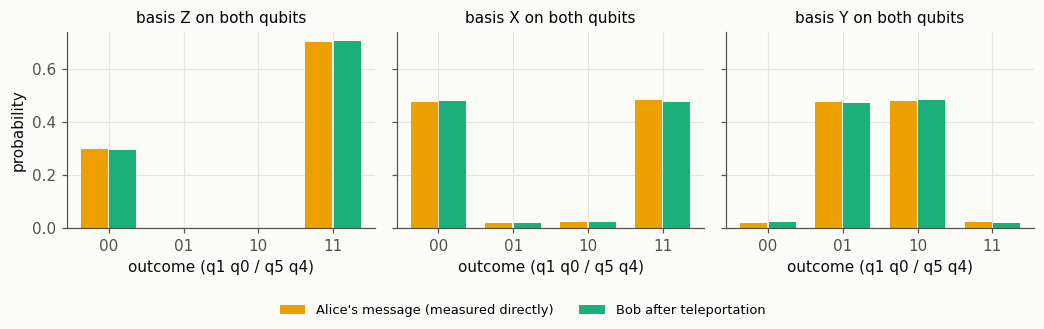

Un-preparation check (8192 shots): `product_HT`: {'00': 8192}; `bell_30_70`: {'00': 8192}.

In [4]:
from telecorr.protocol import bob_counts, circuit
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

def alice_counts(name, basis, shots, seed):
    """The message measured directly on q0, q1 (no teleportation)."""
    qc = QuantumCircuit(2, 2)
    P._prepare(qc, name, 0, 1)
    for q, bq in zip((0, 1), basis):
        if bq == "X": qc.h(q)
        elif bq == "Y": qc.sdg(q); qc.h(q)
    qc.measure([0, 1], [0, 1])
    return AerSimulator().run(qc, shots=shots, seed_simulator=seed).result().get_counts()

shots, keys = 8192, ("00", "01", "10", "11")
name = "bell_30_70"
fig, axs = plt.subplots(1, 3, figsize=(9.6, 3.0), sharey=True)
for ax, basis, s in zip(axs, ("ZZ", "XX", "YY"), (11, 12, 13)):
    a = alice_counts(name, basis, shots, s)
    bo = bob_counts(circuit(name, "measured", basis=basis), shots, seed=s + 100)
    x = np.arange(4); w = 0.38
    ax.bar(x - w / 2, [a.get(k, 0) / shots for k in keys], w * 0.95, color=CONDITION["ceiling"], label="Alice's message (measured directly)")
    ax.bar(x + w / 2, [bo.get(k, 0) / shots for k in keys], w * 0.95, color=CONDITION["noiseless"], label="Bob after teleportation")
    ax.set_xticks(x, keys); ax.set_title(f"basis {basis[0]} on both qubits", fontsize=10); ax.set_xlabel("outcome (q1 q0 / q5 q4)")
axs[0].set_ylabel("probability")
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, fontsize=8.5)
plt.tight_layout(rect=(0, 0.1, 1, 1)); plt.show()
unprep = {n: bob_counts(circuit(n, "measured", unprepare=True), shots, seed=1234) for n in MESSAGES}
show("Un-preparation check (8192 shots): " + "; ".join(f"`{n}`: {c}" for n, c in unprep.items()) + ".")

## Why Bob's corrections matter

Without Alice's bits Bob holds the maximally mixed state; with the bits wired to the wrong gates he holds a
wrong Pauli in most branches. The exact Haar-average fidelity over all two-qubit messages,
F_avg = (4 F_e + 1)/5 with F_e the entanglement fidelity of the protocol (Proposition P1.17), shows how much
each wiring loses:

In [5]:
rows = [(w, P.average_fidelity(frame=w)) for w in P.FRAMES]
show(md_table(rows, ["Bob's corrections", "Haar-average fidelity (exact)"], 4))

| Bob's corrections | Haar-average fidelity (exact) |
|---|---|
| correct | 1.0000 |
| no correction | 0.2500 |
| X and Z bits exchanged | 0.4000 |
| only X corrections | 0.4000 |
| only Z corrections | 0.4000 |

## What it means

* With a perfect channel, teleportation is exactly the identity channel: every message arrives unchanged, and
  Alice's bits reveal nothing about it.
* The correction rule is essential: each of the wrong wirings above drops the average fidelity to 0.40, and
  without Alice's bits Bob is left with 0.25, the value of a random guess.
* The un-preparation check turns "is the message intact?" into a single counted outcome, P(00).

**Next (notebook 2):** the channel qubits q2, q3 are where a real link is noisy. What does noise there do to Bob's
state, and where could it be undone?